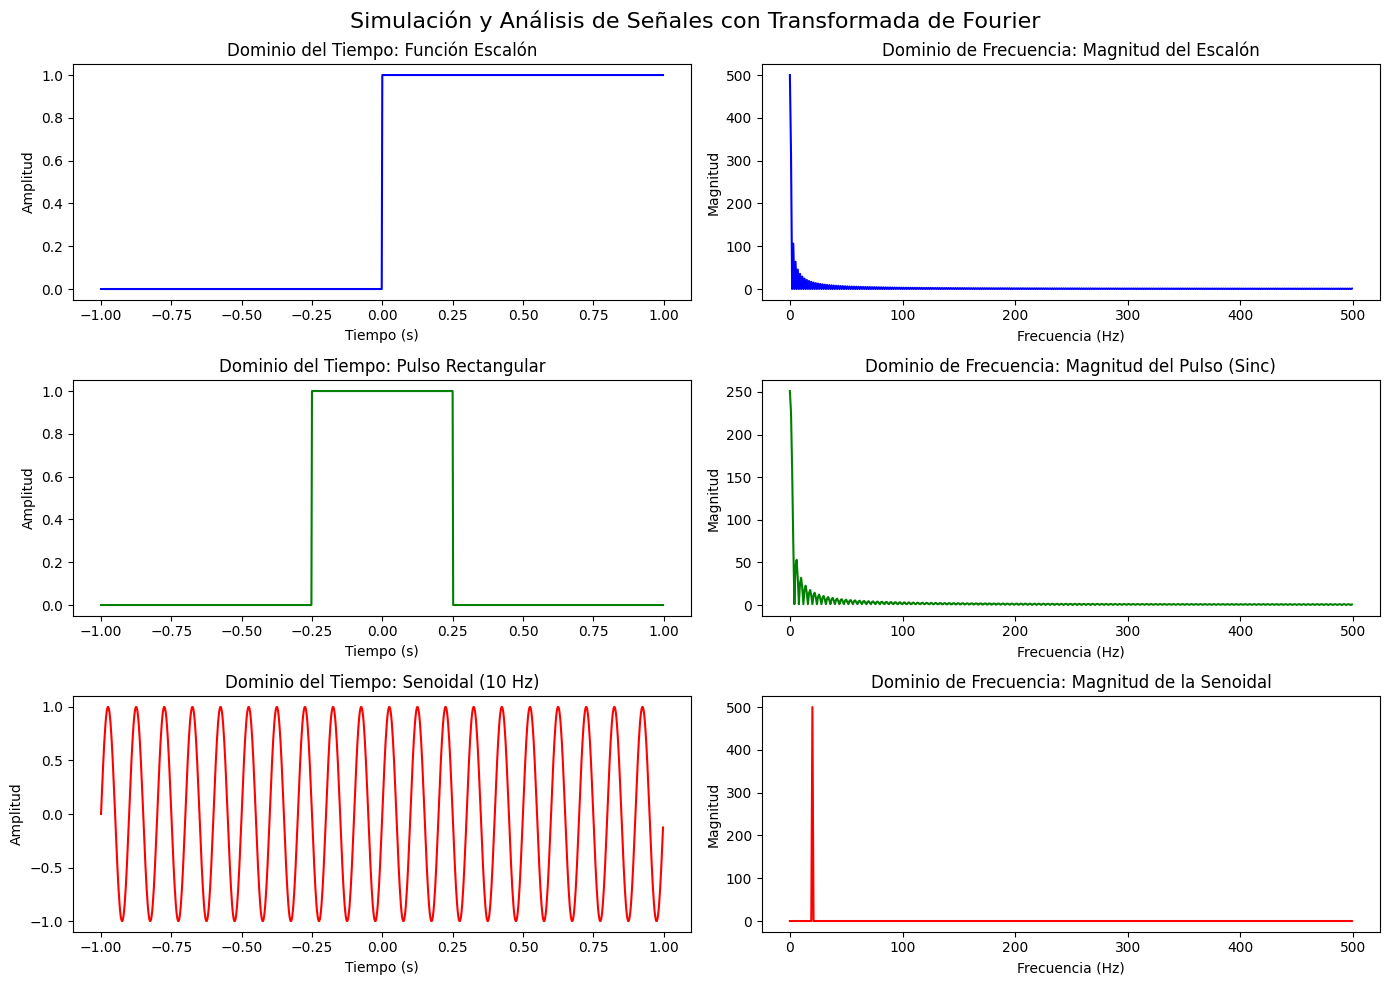


--- Verificación de Propiedades de la Transformada de Fourier ---
1. Linealidad: El error máximo de FFT(Pulso + Seno) - (FFT(Pulso) + FFT(Seno)) es 5.69e-14
   (Un valor cercano a cero confirma la propiedad de linealidad)

2. Desplazamiento en el Tiempo: La diferencia máxima en la magnitud del espectro es 2.00e+00
   (Confirma que desplazar en tiempo no altera la magnitud en frecuencia, solo la fase)

3. Escalamiento (Dualidad): Se generó un pulso más angosto en tiempo.
   Al graficar, se observará que su espectro de frecuencia es más ancho (más disperso).


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# --- CONFIGURACIÓN INICIAL ---
# Definimos la frecuencia de muestreo y el vector de tiempo
fs = 1000  # Frecuencia de muestreo (Hz)
t = np.linspace(-1, 1, fs, endpoint=False) # Vector de tiempo de -1s a 1s

# --- 1. DEFINICIÓN DE SEÑALES EN EL DOMINIO DEL TIEMPO ---
# a) Función Escalón (Heaviside)
escalon = np.heaviside(t, 1)

# b) Pulso Rectangular (Ancho de 0.5s centrado en 0)
pulso = np.where((t >= -0.25) & (t <= 0.25), 1.0, 0.0)

# c) Función Senoidal (Frecuencia de 10 Hz)
f_seno = 10
seno = np.sin(2 * np.pi * f_seno * t)

# --- 2. CÁLCULO DE LA TRANSFORMADA DE FOURIER (FFT) ---
# Calculamos la FFT
fft_escalon = fft(escalon)
fft_pulso = fft(pulso)
fft_seno = fft(seno)

# Calculamos las frecuencias correspondientes
N = len(t)
frecuencias = fftfreq(N, 1/fs)

# Solo tomamos la mitad positiva del espectro (por simetría)
mitad = N // 2

# --- 3. VISUALIZACIÓN (DOMINIO DEL TIEMPO Y FRECUENCIA) ---
fig, axs = plt.subplots(3, 2, figsize=(14, 10))
fig.suptitle('Simulación y Análisis de Señales con Transformada de Fourier', fontsize=16)

# --- Fila 1: Función Escalón ---
axs[0, 0].plot(t, escalon, color='blue')
axs[0, 0].set_title('Dominio del Tiempo: Función Escalón')
axs[0, 0].set_xlabel('Tiempo (s)'); axs[0, 0].set_ylabel('Amplitud')
axs[0, 1].plot(frecuencias[:mitad], np.abs(fft_escalon[:mitad]), color='blue')
axs[0, 1].set_title('Dominio de Frecuencia: Magnitud del Escalón')
axs[0, 1].set_xlabel('Frecuencia (Hz)'); axs[0, 1].set_ylabel('Magnitud')

# --- Fila 2: Pulso Rectangular ---
axs[1, 0].plot(t, pulso, color='green')
axs[1, 0].set_title('Dominio del Tiempo: Pulso Rectangular')
axs[1, 0].set_xlabel('Tiempo (s)'); axs[1, 0].set_ylabel('Amplitud')
axs[1, 1].plot(frecuencias[:mitad], np.abs(fft_pulso[:mitad]), color='green')
axs[1, 1].set_title('Dominio de Frecuencia: Magnitud del Pulso (Sinc)')
axs[1, 1].set_xlabel('Frecuencia (Hz)'); axs[1, 1].set_ylabel('Magnitud')

# --- Fila 3: Función Senoidal ---
axs[2, 0].plot(t, seno, color='red')
axs[2, 0].set_title('Dominio del Tiempo: Senoidal (10 Hz)')
axs[2, 0].set_xlabel('Tiempo (s)'); axs[2, 0].set_ylabel('Amplitud')
axs[2, 1].plot(frecuencias[:mitad], np.abs(fft_seno[:mitad]), color='red')
axs[2, 1].set_title('Dominio de Frecuencia: Magnitud de la Senoidal')
axs[2, 1].set_xlabel('Frecuencia (Hz)'); axs[2, 1].set_ylabel('Magnitud')

plt.tight_layout()
plt.show()

# --- 4. VERIFICACIÓN DE PROPIEDADES ---
print("\n--- Verificación de Propiedades de la Transformada de Fourier ---")

# A) Linealidad: FFT(a + b) = FFT(a) + FFT(b)
suma_tiempo = pulso + seno
fft_suma = fft(suma_tiempo)
fft_individuales = fft_pulso + fft_seno
error_linealidad = np.max(np.abs(fft_suma - fft_individuales))
print(f"1. Linealidad: El error máximo de FFT(Pulso + Seno) - (FFT(Pulso) + FFT(Seno)) es {error_linealidad:.2e}")
print("   (Un valor cercano a cero confirma la propiedad de linealidad)")

# B) Desplazamiento en el tiempo: FFT(x(t - t0)) = FFT(x(t)) * e^(-j*2*pi*f*t0)
t0 = 0.1 # Desplazamiento de 0.1s
pulso_desplazado = np.where((t >= -0.25 + t0) & (t <= 0.25 + t0), 1.0, 0.0)
fft_pulso_desplazado = fft(pulso_desplazado)
# Teóricamente, la magnitud del espectro no cambia, solo la fase.
error_magnitud = np.max(np.abs(np.abs(fft_pulso) - np.abs(fft_pulso_desplazado)))
print(f"\n2. Desplazamiento en el Tiempo: La diferencia máxima en la magnitud del espectro es {error_magnitud:.2e}")
print("   (Confirma que desplazar en tiempo no altera la magnitud en frecuencia, solo la fase)")

# C) Escalamiento en Frecuencia (Dualidad tiempo-frecuencia)
# Una señal más angosta en tiempo, es más ancha en frecuencia.
pulso_angosto = np.where((t >= -0.05) & (t <= 0.05), 1.0, 0.0) # Pulso más angosto
fft_pulso_angosto = fft(pulso_angosto)
print("\n3. Escalamiento (Dualidad): Se generó un pulso más angosto en tiempo.")
print("   Al graficar, se observará que su espectro de frecuencia es más ancho (más disperso).")

